In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)
from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson

import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from matplotlib import font_manager
font_manager.fontManager.addfont("../../../../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 18,
    "pdf.fonttype": 42,       # Embed TrueType fonts in PDF
})

/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [2]:
train_data = sc.read_h5ad("../../input/diff_train.h5ad")
print("train original data:", train_data)
# print(train_data.obs)
train_data.obs["day_types"] = train_data.obs["Group"]
# train_data.obs.loc[train_data.obs["day_types"] == 0, "weight_types"] = 0
# train_data.obs.loc[train_data.obs["day_types"] == 3, "weight_types"] = 1

# print(train_data.obs["weight_types"].unique())
print(train_data.obs["day_types"].unique())
# print(train_data.obs["cluster_types"].unique())

train original data: AnnData object with n_obs × n_vars = 2400 × 203
    obs: 'Group'
[3, 0]
Categories (2, int64): [3, 0]


In [3]:
test_data = sc.read_h5ad("../../input/diff_test.h5ad")
print("test original data:", test_data)
# print(train_data.obs)
test_data.obs["day_types"] = test_data.obs["Group"]
# train_data.obs.loc[train_data.obs["day_types"] == 0, "weight_types"] = 0
# train_data.obs.loc[train_data.obs["day_types"] == 3, "weight_types"] = 1

# print(train_data.obs["weight_types"].unique())
print(test_data.obs["day_types"].unique())
# print(train_data.obs["cluster_types"].unique())

test original data: AnnData object with n_obs × n_vars = 2400 × 203
    obs: 'Group'
[1, 3, 0, 2]
Categories (4, int64): [1, 3, 0, 2]


In [3]:
import anndata as ad
# interp = train_data.copy()
# # interp = ad.concat([data_filtered, train_data], axis=0, join="inner")
# #new start
train_data.X = train_data.X.astype("float64")
interp = train_data.copy()

idx = interp.obs.sort_values(["day_types"]).index
interp_all = interp[idx].copy()
# interp_all = interp_1[interp_1.obs["cluster_types"].sort_values().index].copy()
print(interp_all)
# print(interp_all.obs["weight_types"].unique())
print(interp_all.obs["day_types"].unique())
# print(interp_all.obs["cluster_types"].unique())

AnnData object with n_obs × n_vars = 2400 × 203
    obs: 'Group', 'day_types'
[3, 0]
Categories (2, int64): [3, 0]


Cells × genes: (2400, 203)
computing PCA
    with n_comps=50


    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 30
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:06)
computing Diffusion Maps using n_comps=15(=n_dcs)
computing transitions
    finished (0:00:00)
    eigenvalues of transition matrix
    [1.         0.9945431  0.9727171  0.9531929  0.9486142  0.9426301
     0.92143834 0.8962945  0.8900116  0.8839973  0.8682282  0.8632686
     0.8519588  0.847229   0.84190327]
    finished: added
    'X_diffmap', diffmap coordinates (adata.obsm)
    'diffmap_evals', eigenvalues of transition matrix (adata.uns) (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running PAGA
    finished: added
    'paga/connectivities', connec

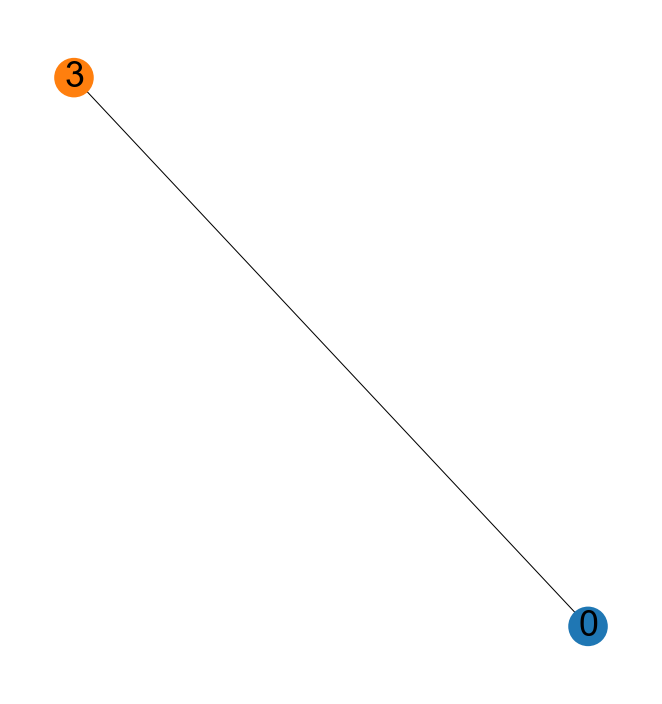

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:05)
Root cells: 1200
computing Diffusion Pseudotime using n_dcs=10
    finished: added
    'dpt_pseudotime', the pseudotime (adata.obs) (0:00:00)
25475_4#319-day3    0.920389
25271_4#350-day3    0.971354
23794_7#94-day3     0.839236
24327_4#45-day3     0.833857
25344_8#324-day3    0.878191
                      ...   
23794_1#236-day0    0.171521
24252_5#80-day0     0.066643
25271_8#177-day0    0.085452
21672_1#31-day0     0.070139
24229_3#217-day0    0.140972
Name: dpt_pseudotime, Length: 2400, dtype: float32


In [ ]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

sc.settings.verbosity = 3
sc.settings.set_figure_params(
    dpi=100,
    frameon=False,
    figsize=(4, 4),
    facecolor="white"
)
interp_all_ann = interp_all.copy()

# day_types used for PAGA trajectory
interp_all_ann.obs["day_types"] = pd.to_numeric(interp_all_ann.obs["day_types"])
interp_all_ann.obs["day_types"] = interp_all_ann.obs["day_types"].astype("category")

print("Cells × genes:", interp_all_ann.shape)

if "highly_variable" in interp_all_ann.var:
    print("Highly variable genes:",
          interp_all_ann.var["highly_variable"].sum())
# PCA
sc.tl.pca(interp_all_ann, svd_solver="arpack")
sc.pp.neighbors(interp_all_ann, n_neighbors=15, n_pcs=30)

sc.tl.diffmap(interp_all_ann)
sc.pp.neighbors(interp_all_ann)


# PAGA using day_types
sc.tl.paga(interp_all_ann, groups="day_types")

sc.pl.paga(
    interp_all_ann,
    color=["day_types"]
)

sc.tl.umap(interp_all_ann)


# Choose root from starting day
root_day = 0

root_mask = interp_all_ann.obs["day_types"] == root_day

print("Root cells:", root_mask.sum())

interp_all_ann.uns["iroot"] = np.flatnonzero(root_mask)[0]

# DPT pseudotime
sc.tl.dpt(interp_all_ann)
print(interp_all_ann.obs["dpt_pseudotime"])


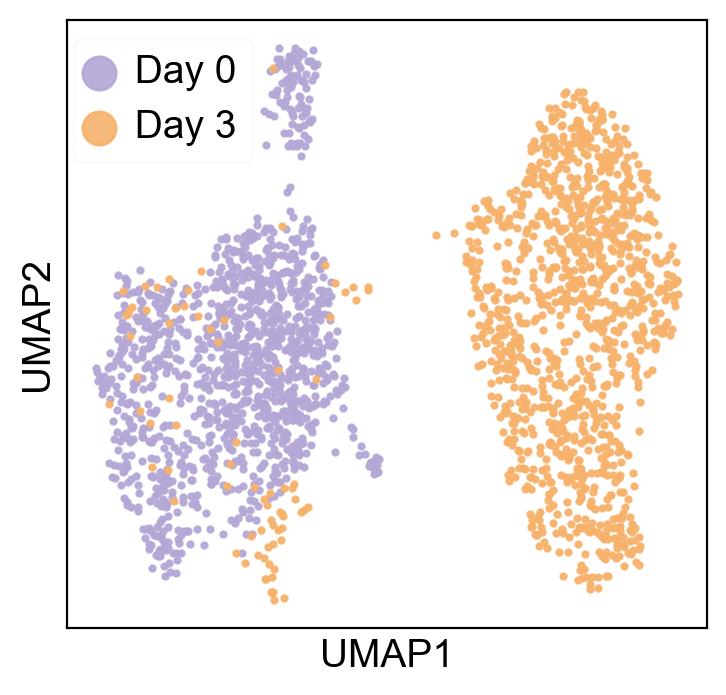

In [7]:

fig,ax = plt.subplots(figsize=(4.1, 4))
X_umap = interp_all_ann.obsm["X_umap"]

mask_0 = interp_all_ann.obs["day_types"] == 0
mask_3 = interp_all_ann.obs["day_types"] == 3

plt.scatter(
    X_umap[mask_0, 0],
    X_umap[mask_0, 1],
    c="#B4A7D6",
    s=4,
    alpha=0.9,
    label=" Day 0"
)

plt.scatter(
    X_umap[mask_3, 0],
    X_umap[mask_3, 1],
    c="#F6B26B",
    s=4,
    alpha=0.9,
    label=" Day 3"
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(True)
ax.set_xticks([])
ax.set_yticks([])
ax.legend(
    loc="upper right",
    bbox_to_anchor=(0.32, 1),
    markerscale=6,
    scatterpoints=1,
    prop={"size": 14, "weight": "bold"},
    frameon=True,
    facecolor="white",
    edgecolor="lightgray",
    framealpha=0.1
)
#plt.axis("off")
# plt.title("combined umap marked training data")
fig.savefig(os.path.join(f"umap_with_training_data.pdf"), bbox_inches="tight")
plt.show()




View of AnnData object with n_obs × n_vars = 1200 × 203
    obs: 'Group', 'day_types', 'dpt_pseudotime'
    uns: 'pca', 'neighbors', 'diffmap_evals', 'paga', 'day_types_sizes', 'day_types_colors', 'umap', 'iroot'
    obsm: 'X_pca', 'X_diffmap', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
                 day_types  dpt_pseudotime
24475_3#257-day0         0        0.000000
25262_8#259-day0         0        0.153092
25619_7#130-day0         0        0.127974
25271_7#348-day0         0        0.081778
23794_1#104-day0         0        0.169418


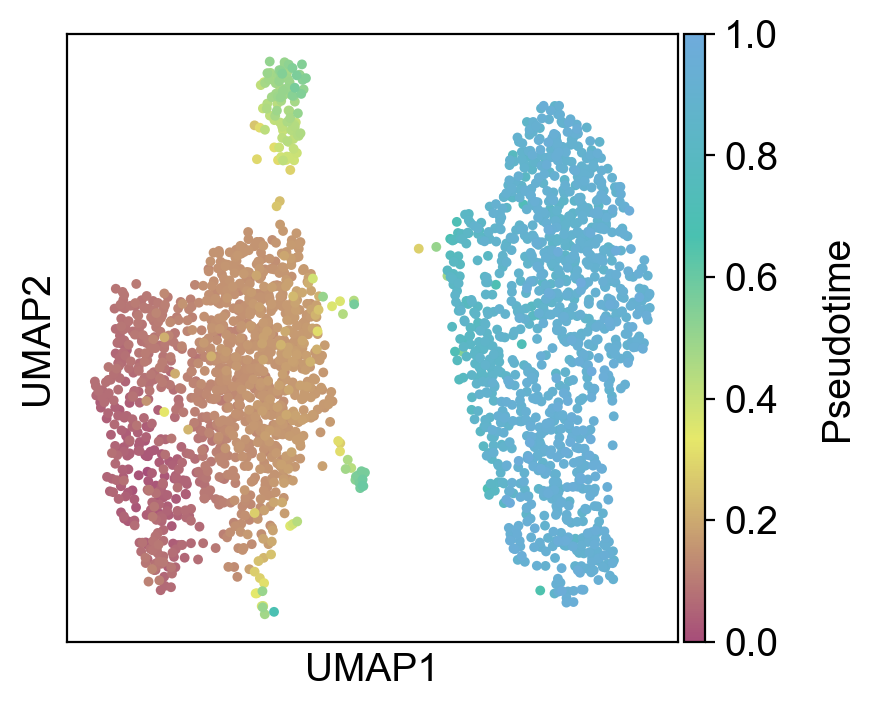

In [6]:
from matplotlib.colors import LinearSegmentedColormap

fig, ax = plt.subplots(figsize=(4.3, 4))
my_cmap = LinearSegmentedColormap.from_list(
    "my_pseudotime",
    ["#A64D79","#E6E86A","#4AC1B0","#6FABDC"]
)

sc.pl.umap(
    interp_all_ann,
    color="dpt_pseudotime",
    cmap=my_cmap,
    title="",
    na_color="black",
    ax=ax,
    show=False
)
mask_0 = interp_all_ann.obs["day_types"] == 0
print(interp_all_ann[mask_0])
print(interp_all_ann.obs.loc[mask_0, ["day_types","dpt_pseudotime"]].head())
# fig = plt.gcf()

# fig = plt.gcf()
ax.set_axis_on()
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(True)

ax.set_xticks([])
ax.set_yticks([])
cbar_ax = fig.axes[-1]
cbar_ax.set_ylabel("Pseudotime", rotation=90, labelpad=15)
cbar_ax.yaxis.set_label_position("right")
# fig.savefig(setting["filename"], bbox_inches="tight")
# plt.show()
# plt.close(fig)
fig.savefig(os.path.join(f"umap_pseudotime_training_data.pdf"), bbox_inches="tight")
plt.show()